# Hand-picked SAM prompts for each camera calibration period
csherwood@usgs.gov, 2026-10-28, generated with Claude Opus 5.5

For each camera and EO calibration file (each period over which one EO is valid), this notebook shows one good
image: the highest image quality, near local noon, at about mid-tide. Drawn on it are the Otsu waterlines of
up to 12 images spanning that period's tide range, colored by water level (blue low, red high). You click:

1. **LAND** points (yellow): along the beach, just landward of the highest waterline you expect (high tide plus
   runup). Press **Enter** when done.
2. **WATER** points (cyan): along the beach, just seaward of the lowest waterline. Press **Enter** when done.

Left click adds a point, right click or Backspace removes the last one. Clicking both sets in the same direction
along the beach is tidiest, but the order is fixed if not. The polygon the two sets outline (white dashed) is
then shown; close the window to move to the next period. Six to ten points per set is usually plenty; put
extra points where the beach bends or the roll is strongest.

In `marconi_sam`, land points are SAM background prompts, water points foreground prompts, and the waterline
is kept only inside the polygon. Each period is saved to `PROMPT_CSV` as soon as it is done, so you can stop and
rerun; to redo periods, list their EO files in `REDO`.

Clicking needs an interactive window: the click cell uses `%matplotlib qt` (needs PyQt or PySide, which most
conda environments with matplotlib already have). If the toolbar zoom or pan is on, turn it off before clicking.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import marconi_prompts as mp

# --- config
PROJ = Path(r'F:\crs\proj\2026_wl_dems')
OUT_DIR = PROJ / 'scan'
SCAN_CSV = OUT_DIR / 'image_scan.csv'
WL_CSV = OUT_DIR / 'waterlines_px.csv'
PROMPT_CSV = OUT_DIR / 'sam_prompts.csv'
FIG_DIR = PROJ / 'fig'
FIRST_DAY, LAST_DAY = None, None      # limit the images considered, e.g. '2024-12-01', '2025-03-31'; None = all
REDO = []                             # EO files whose prompts should be clicked again
PROMPT = mp.PROMPT | {}               # e.g. {'hours': (11, 15), 'n_overlay': 20}

scan = pd.read_csv(SCAN_CSV, parse_dates=['time'])
scan = scan[(scan.time >= pd.Timestamp(FIRST_DAY or scan.time.min())) & (scan.time <= pd.Timestamp(LAST_DAY or scan.time.max()))]
wl_px = pd.read_csv(WL_CSV).groupby('path')
pers = mp.periods(scan)
pers

,camera,eo_file,station,io_file,t_first,t_last,n_img
0,c1,CACO03_c1_20241023_EO.yaml,CACO03,CACO03_c1_20240801_IO.yaml,2024-12-12 17:30:00,2025-01-03 17:30:00,128
1,c1,CACO03_c1_20250123_EO.yaml,CACO03,CACO03_c1_20240801_IO.yaml,2025-01-08 12:30:00,2025-01-23 16:30:00,192
2,c1,CACO04_c1_20250219_EO.yaml,CACO04,CACO03_c1_20240801_IO.yaml,2025-01-25 12:00:00,2025-03-10 15:00:00,682
3,c2,CACO03_c2_20241023_EO.yaml,CACO03,CACO03_c2_20240801_IO.yaml,2024-12-09 18:00:00,2025-01-03 20:30:00,221
4,c2,CACO03_c2_20250123_EO.yaml,CACO03,CACO03_c2_20240801_IO.yaml,2025-01-08 12:30:00,2025-01-23 16:30:00,215
5,c2,CACO04_c2_20250219_EO.yaml,CACO04,CACO03_c2_20240801_IO.yaml,2025-01-25 12:00:00,2025-03-10 15:00:00,768


In [2]:
%matplotlib qt
prompts = mp.collect(scan, wl_px, PROMPT_CSV, REDO, PROMPT)

6 of 6 periods to do
c1 CACO03_c1_20241023_EO.yaml 16 land, 12 water
c1 CACO03_c1_20250123_EO.yaml 16 land, 18 water
c1 CACO04_c1_20250219_EO.yaml 14 land, 16 water
c2 CACO03_c2_20241023_EO.yaml 17 land, 21 water
c2 CACO03_c2_20250123_EO.yaml 17 land, 19 water
c2 CACO04_c2_20250219_EO.yaml 26 land, 22 water


## Review
All periods on one figure (`fig/sam_prompts.png`). Rerun the click cell with an EO file in `REDO` to fix one.

label                              land  water
camera eo_file                                
c1     CACO03_c1_20241023_EO.yaml    16     12
       CACO03_c1_20250123_EO.yaml    16     18
       CACO04_c1_20250219_EO.yaml    14     16
c2     CACO03_c2_20241023_EO.yaml    17     21
       CACO03_c2_20250123_EO.yaml    17     19
       CACO04_c2_20250219_EO.yaml    26     22


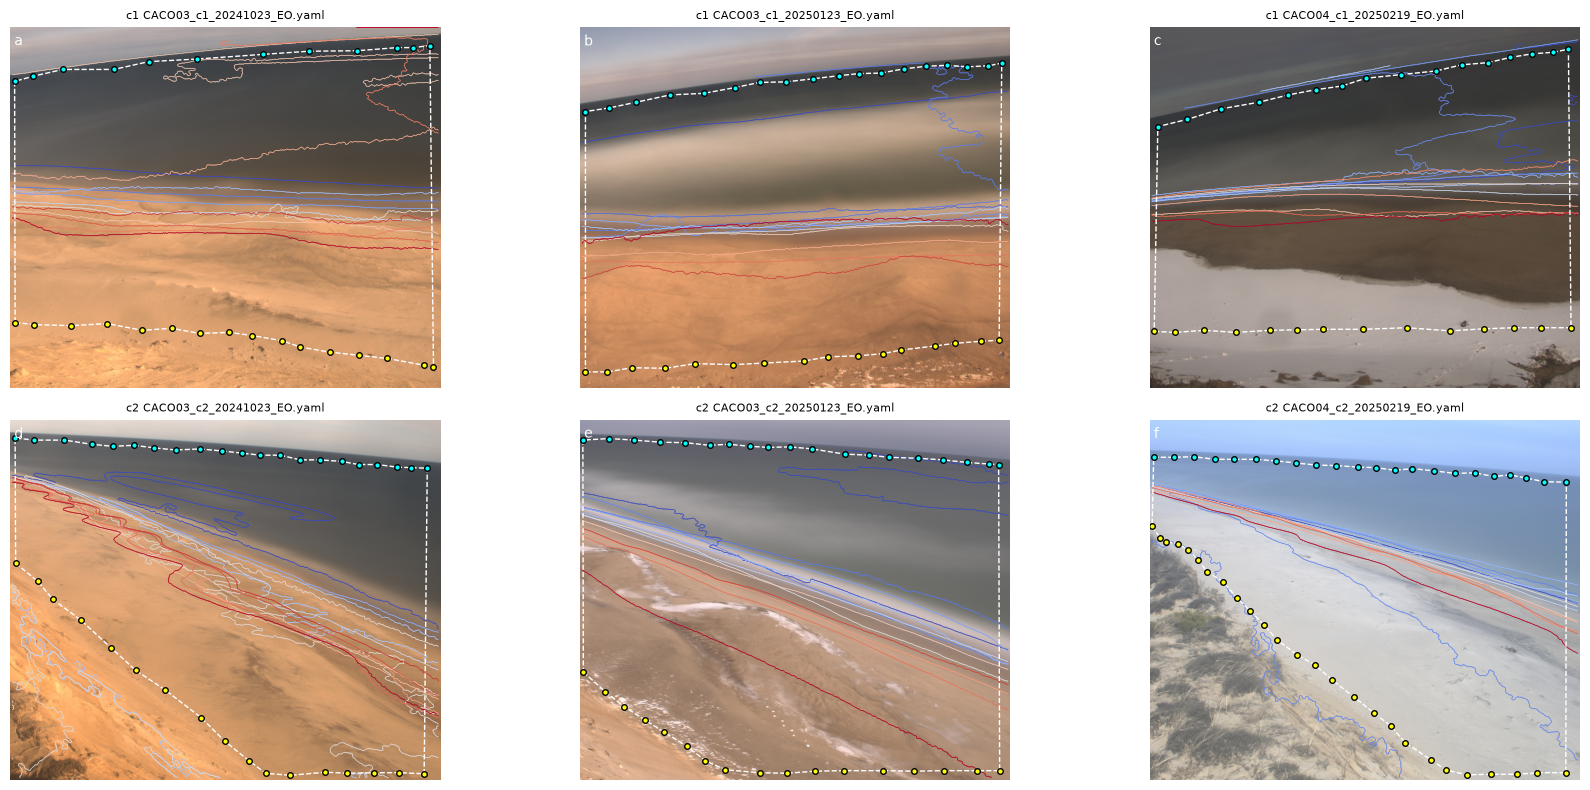

In [3]:
%matplotlib inline
prompts = pd.read_csv(PROMPT_CSV, parse_dates=['t_first', 't_last'])
print(prompts.groupby(['camera', 'eo_file', 'label']).size().unstack())
fig = mp.review(prompts, scan, wl_px, FIG_DIR / 'sam_prompts.png', PROMPT)

## Using the prompts
In `qc_waterlines.ipynb`, the SAM cell reads `sam_prompts.csv` if it exists and passes it to
`msam.detect_all_sam(..., prompts=prompts)`. Images from periods without hand-picked prompts fall back to the
geometric prompts; the `hand_prompts` column of the returned table says which were used. Delete
`waterlines_px_sam.csv` (or rename it) before rerunning, since detection resumes and skips images already done.